# Peak SWE and peak streamflow

Spearman rank correlation between **water-year peak observed SWE** and **water-year peak observed streamflow** at Ross.

SWE is NorSWE `snw` (`kg m-2`), with the two Twin Creeks snow surveys combined the same way as in `explore_swe_quantile_mapping`: `CanSWE-YT-09BA-SC02A` and `CanSWE-YT-09BA-SC02B` become one record (`CanSWE-YT-09BA-SC02`). Dates reported by only one survey keep that value; overlapping dates use the arithmetic mean. The correlation uses this observed SWE, not the model-equivalent series from quantile mapping.

Set `STATION_ID` to the station to assess. It may be a `station_id` or a `station_name`. Only that station is paired with streamflow and scored.

Streamflow is daily discharge (`m3 s-1`) at the Ross gauge.

The water year starts on **1 October**, so the snow-season SWE maximum is paired with the melt-season streamflow maximum that follows it. A water year enters the correlation only when:

- SWE has at least one finite observation in March–May (the sample reaches the usual peak season; a year that ends in December is excluded),
- streamflow has at least one finite observation in May–July (the freshet was observed).

The peak itself is the maximum finite value over the whole water year, not only inside that window. For the snow surveys, that maximum is the largest survey of the year, not a continuous seasonal maximum.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from snowda.io.streamflow import read_streamflow_observations
from snowda.obs_qm import combine_stations, read_swe_observations, water_year

%matplotlib inline

SWE_PATH = Path("/Users/dcasson/Data/snow_data/NorSWE/Ross_Lumped_NorSWE.nc")
OBS_CSV = Path("/Users/dcasson/Data/snowda/summa/ross_lumped/observations/streamflow.csv")

WY_START_MONTH = 10
SWE_SEASON_MONTHS = (3, 4, 5)
FLOW_SEASON_MONTHS = (5, 6, 7)
MIN_YEARS = 3

# Station used for the correlation (station_id or station_name).
#   CanSWE-YT-09BA-M5    TWIN CREEKS A
#   CanSWE-YT-09BA-M7    TWIN CREEKS B
#   CanSWE-YT-09BA-SC02  TWIN CREEKS combined
STATION_ID = "CanSWE-YT-09BA-SC02"

## Water-year peaks

`STATION_ID` is paired with the gauge. Overlapping water years are the sample for Spearman’s ρ. The catalog lists every station so the id or name can be changed and the notebook re-run.

In [8]:
def _finite_frame(times, values, value_name: str) -> pd.DataFrame:
    index = pd.DatetimeIndex(times)
    frame = pd.DataFrame(
        {
            "time": index,
            "water_year": water_year(index, start_month=WY_START_MONTH),
            value_name: np.asarray(values, dtype=float),
        }
    )
    return frame[np.isfinite(frame[value_name])].copy()


def water_year_peaks(frame: pd.DataFrame, value_name: str, season_months) -> pd.DataFrame:
    """Maximum in each water year that has an observation inside ``season_months``."""
    rows = []
    for year, group in frame.groupby("water_year"):
        in_season = group["time"].dt.month.isin(season_months)
        if not bool(in_season.any()):
            continue
        idx = group[value_name].idxmax()
        rows.append(
            {
                "water_year": int(year),
                f"peak_{value_name}": float(group.loc[idx, value_name]),
                f"peak_{value_name}_date": pd.Timestamp(group.loc[idx, "time"]),
                f"n_{value_name}": int(len(group)),
            }
        )
    return pd.DataFrame(rows)


obs_ds = read_swe_observations(SWE_PATH)
obs_ds = combine_stations(
    obs_ds,
    ["CanSWE-YT-09BA-SC02A", "CanSWE-YT-09BA-SC02B"],
    new_id="CanSWE-YT-09BA-SC02",
    new_name="TWIN CREEKS combined",
)
snw = obs_ds["snw"]

flow = read_streamflow_observations(OBS_CSV)
flow_peaks = water_year_peaks(
    _finite_frame(flow.time.values, flow.values, "q"),
    "q",
    FLOW_SEASON_MONTHS,
)

paired_parts = []
for sid in snw.station_id.values:
    series = snw.sel(station_id=sid)
    swe_peaks = water_year_peaks(
        _finite_frame(series.time.values, series.values, "swe"),
        "swe",
        SWE_SEASON_MONTHS,
    )
    merged = swe_peaks.merge(flow_peaks, on="water_year", how="inner")
    merged.insert(0, "station_id", str(sid))
    merged.insert(
        1,
        "station_name",
        str(obs_ds["station_name"].sel(station_id=sid).values),
    )
    paired_parts.append(merged)

paired_all = pd.concat(paired_parts, ignore_index=True)
obs_ds.close()

catalog = (
    paired_all.groupby(["station_id", "station_name"], sort=False)
    .size()
    .rename("n_years")
    .reset_index()
)
match = (catalog["station_id"] == STATION_ID) | (catalog["station_name"] == STATION_ID)
if int(match.sum()) != 1:
    choices = catalog.to_string(index=False)
    raise ValueError(
        f"STATION_ID {STATION_ID!r} does not match one station. "
        f"Choose a station_id or station_name from:\n{choices}"
    )
chosen_id = str(catalog.loc[match, "station_id"].iloc[0])
paired = paired_all.loc[paired_all["station_id"] == chosen_id].reset_index(drop=True)
print(
    f"Selected {paired['station_name'].iloc[0]} ({chosen_id}), "
    f"{len(paired)} water years"
)
catalog

Selected TWIN CREEKS combined (CanSWE-YT-09BA-SC02), 43 water years


,station_id,station_name,n_years
0,CanSWE-YT-09BA-M5,TWIN CREEKS A,8
1,CanSWE-YT-09BA-M7,TWIN CREEKS B,2
2,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,43


## Spearman correlation

ρ is computed on the paired water years for the selected station. Fewer than three overlapping years are plotted but not assigned a coefficient.

In [9]:
def _spearman(group: pd.DataFrame) -> tuple[float, float]:
    if len(group) < MIN_YEARS:
        return np.nan, np.nan
    result = spearmanr(group["peak_swe"], group["peak_q"])
    return float(result.statistic), float(result.pvalue)


summary_rows = []
for sid, group in paired.groupby("station_id", sort=False):
    rho, p_value = _spearman(group)
    summary_rows.append(
        {
            "station_id": sid,
            "station_name": group["station_name"].iloc[0],
            "n_years": int(len(group)),
            "first_water_year": int(group["water_year"].min()),
            "last_water_year": int(group["water_year"].max()),
            "spearman_rho": rho,
            "p_value": p_value,
        }
    )
summary = pd.DataFrame(summary_rows)

for row in summary.itertuples(index=False):
    if np.isfinite(row.spearman_rho):
        print(
            f"{row.station_name} ({row.station_id}): "
            f"Spearman ρ = {row.spearman_rho:.3f} "
            f"(n = {row.n_years}, p = {row.p_value:.3g})"
        )
    else:
        print(
            f"{row.station_name} ({row.station_id}): "
            f"n = {row.n_years} overlapping water years; "
            f"Spearman not computed (need at least {MIN_YEARS})."
        )

summary

TWIN CREEKS combined (CanSWE-YT-09BA-SC02): Spearman ρ = 0.740 (n = 43, p = 1.4e-08)


,station_id,station_name,n_years,first_water_year,last_water_year,spearman_rho,p_value
0,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,43,1979,2021,0.740313,1.395096e-08


/var/folders/46/6y3tkg051374dmsgd2w6l9gw0000gn/T/ipykernel_28178/2514909572.py:47: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper left", framealpha=0.9)


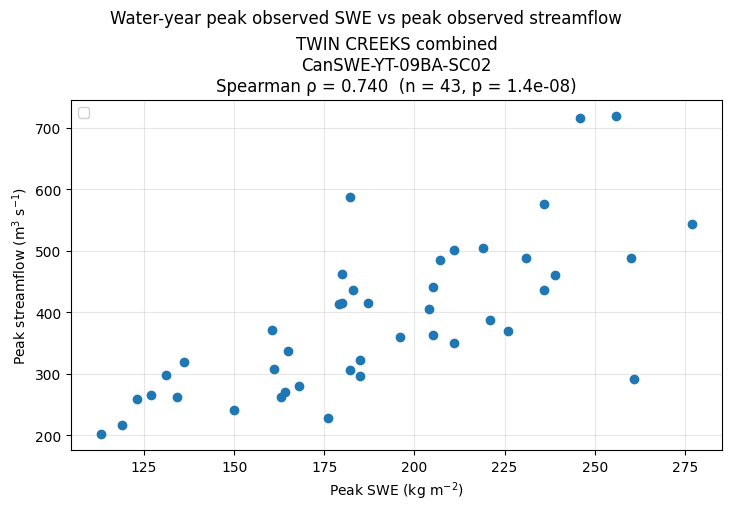

In [13]:
station_ids = list(summary["station_id"])
n_sta = len(station_ids)
fig, axes = plt.subplots(
    1,
    n_sta,
    figsize=(7.2 if n_sta == 1 else 4.6 * n_sta, 5.0),
    sharey=False,
    squeeze=False,
    layout="constrained",
)
axes = axes[0]

for ax, sid in zip(axes, station_ids):
    group = paired.loc[paired["station_id"] == sid]
    row = summary.loc[summary["station_id"] == sid].iloc[0]
    ax.scatter(group["peak_swe"], group["peak_q"], s=36, color="C0", zorder=3)
    if len(group) <= 12:
        for sample in group.itertuples(index=False):
            ax.annotate(
                str(int(sample.water_year)),
                (sample.peak_swe, sample.peak_q),
                textcoords="offset points",
                xytext=(4, 4),
                fontsize=8,
                color="0.35",
            )
    if np.isfinite(row["spearman_rho"]):
        stats = (
            f"Spearman ρ = {row['spearman_rho']:.3f}  "
            f"(n = {int(row['n_years'])}, p = {row['p_value']:.3g})"
        )
    else:
        stats = f"n = {int(row['n_years'])} (need ≥ {MIN_YEARS} years)"
    ax.set_title(f"{row['station_name']}\n{sid}\n{stats}")
    if len(group) <= 12:
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(ymin, ymax + 0.12 * (ymax - ymin))
    ax.set_xlabel(r"Peak SWE (kg m$^{-2}$)")
    ax.grid(True, alpha=0.3)
    xmin, xmax = ax.get_xlim()
    ymin, ymax = ax.get_ylim()
    lo = max(xmin, ymin)
    hi = min(xmax, ymax)
    if hi > lo:
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)
        ax.legend(loc="upper left", framealpha=0.9)

axes[0].set_ylabel(r"Peak streamflow (m$^3$ s$^{-1}$)")
fig.suptitle("Water-year peak observed SWE vs peak observed streamflow")
plt.show()

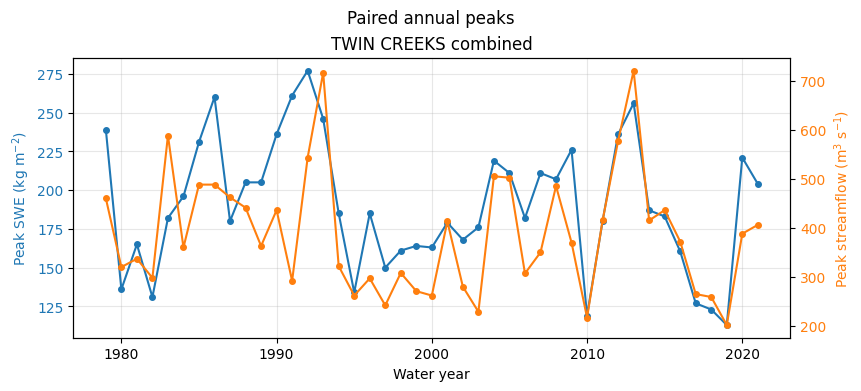

In [11]:
fig, axes = plt.subplots(
    n_sta,
    1,
    figsize=(8.5, 3.8 if n_sta == 1 else 2.8 * n_sta),
    squeeze=False,
    layout="constrained",
)
axes = axes[:, 0]

for ax, sid in zip(axes, station_ids):
    group = paired.loc[paired["station_id"] == sid].sort_values("water_year")
    name = group["station_name"].iloc[0]
    ax.plot(
        group["water_year"],
        group["peak_swe"],
        color="C0",
        marker="o",
        ms=4,
        label="Peak SWE",
    )
    ax.set_ylabel(r"Peak SWE (kg m$^{-2}$)", color="C0")
    ax.tick_params(axis="y", labelcolor="C0")
    ax2 = ax.twinx()
    ax2.plot(
        group["water_year"],
        group["peak_q"],
        color="C1",
        marker="o",
        ms=4,
        label="Peak streamflow",
    )
    ax2.set_ylabel(r"Peak streamflow (m$^3$ s$^{-1}$)", color="C1")
    ax2.tick_params(axis="y", labelcolor="C1")
    if len(group) <= 12:
        years = group["water_year"].astype(int).tolist()
        ax.set_xticks(years)
    ax.set_title(name)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Water year")
fig.suptitle("Paired annual peaks")
plt.show()

## Paired water years

`n_swe` is the number of finite SWE observations in that water year. Survey peaks are the largest of those surveys.

In [12]:
table = paired.copy()
table["peak_swe_date"] = pd.to_datetime(table["peak_swe_date"]).dt.strftime("%Y-%m-%d")
table["peak_q_date"] = pd.to_datetime(table["peak_q_date"]).dt.strftime("%Y-%m-%d")
table = table.sort_values(["station_name", "water_year"]).reset_index(drop=True)
table

,station_id,station_name,water_year,peak_swe,peak_swe_date,n_swe,peak_q,peak_q_date,n_q
0,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1979,239.0,1979-04-03,4,460.0,1979-06-06,365
1,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1980,136.0,1980-04-30,5,320.0,1980-05-17,366
2,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1981,165.0,1981-02-28,6,337.0,1981-05-24,365
3,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1982,131.0,1982-03-29,5,298.0,1982-06-03,365
4,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1983,182.0,1983-03-31,4,588.0,1983-06-04,365
5,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1984,196.0,1984-04-29,5,360.0,1984-06-11,366
6,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1985,231.0,1985-04-29,5,488.0,1985-06-07,365
7,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1986,260.0,1986-04-29,4,488.0,1986-06-02,365
8,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1987,180.0,1987-03-31,4,462.0,1987-06-06,365
9,CanSWE-YT-09BA-SC02,TWIN CREEKS combined,1988,205.0,1988-03-29,4,441.0,1988-05-17,366
